# Modelo Predictivo de Disrupciones Aéreas (Propagación Causal en Red + Rotación Intradía)
### Ingeniería de Características Autorregresivas ($s - 1$), Codificación Bayesiana Out-of-Fold y Calibración Operativa

---

## Objetivo de Negocio y Metodología de Ciencia de Datos Aplicada
El objetivo es predecir con la máxima precisión, sensibilidad y discriminación posibles si un vuelo comercial sufrirá una **disrupción operativa severa** (`is_delayed_or_cancelled = 1` si `Dep_Delay >= 15` min o `Cancelled == 1`).

### Por qué este Modelo Alcanza `ROC-AUC = 0.7898` y `PR-AUC = 0.6112` (100% Causal, Cero Fuga):
En un sistema de transporte aéreo en red, los vuelos no son eventos aislados; el tiempo fluye secuencialmente a través de los bloques horarios del día:
$$\text{Día }(t-1) \longrightarrow \text{Morning }(s=1) \longrightarrow \text{Afternoon }(s=2) \longrightarrow \text{Evening }(s=3) \longrightarrow \text{Night }(s=4)$$
Antes de que despegue cualquier vuelo en el bloque horario $s$, **todo lo ocurrido en el bloque horario anterior ($s - 1$)** ya es un hecho histórico conocido en el Centro de Control de Operaciones (OCC):
1. **Propagación Intradía de la Aeronave (`Tail_Number` Turnaround State):** Si la aeronave asignada sufrió retraso en su tramo previo del mismo día (`tail_sameday_prev_dep_delay`, `tail_sameday_prev_arr_delay`), el margen de rotación en tierra (*turnaround buffer* de 35-45 min) se absorbe y la demora se transmite al siguiente vuelo.
2. **Estado Causal del Hub de Origen y Destino (`slot_order - 1`):** Tasa de disrupción, cancelación y minutos medios de demora por Clima, Control Aéreo (NAS) y Aeronave Tardía en el bloque horario inmediatamente anterior (`hub_dep_prev_*`, `hub_arr_prev_*`).
3. **Presión Sistémica de la Aerolínea (`air_sys_prev_*`, `air_dep_prev_*`):** Nivel de congestión operativa de la aerolínea en el bloque previo.
4. **Meteorología Dual (Origen + Destino) y Física Atmosférica:** Riesgo de deshielo en pista (`deicing_risk`), caída de presión barométrica (`pres_drop`), amplitud térmica (`temp_swing`) y precipitación/viento combinados en la ruta.
5. **Target Encoding Bayesiano Out-of-Fold (`StratifiedKFold(5)`):** Codificación regularizada de rutas e interacciones espacio-temporales (`route`, `dep_x_time`, `arr_x_time`, `airline_x_time`, `dep_x_month`, `airline_x_dep`).


In [1]:
import os
import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, f1_score, precision_score, recall_score, accuracy_score
)
from sklearn.inspection import permutation_importance

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

import config
config.ensure_dirs()

print(" Librerías importadas y entorno inicializado.")


 Librerías importadas y entorno inicializado.


## 1. Carga del Dataset Causal Enriquecido desde la Capa Oro
Cargamos la matriz `ml_features_dataset.parquet` (300,000 vuelos x 58 variables base).


In [2]:
ml_features_path = config.GOLD_DIR / "ml_features_dataset.parquet"
print(f"Cargando dataset desde Capa Oro: {ml_features_path.name}")
df = pd.read_parquet(ml_features_path)
print(f"Dataset cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas.")
df.head(5)


Cargando dataset desde Capa Oro: ml_features_dataset.parquet
Dataset cargado: 300,000 filas x 58 columnas.


,FlightDate,Day_Of_Week,airline,Tail_Number,dep_airport,arr_airport,DepTime_label,Dep_Delay,Cancelled,Flight_Duration,...,snow,wspd,pres,arr_tavg,arr_tmin,arr_tmax,arr_prcp,arr_snow,arr_wspd,arr_pres
0,2023-01-16,1,PSA AIRLINES,N599NN,MEM,PHL,AFTERNOON,-1.0,0,149.0,...,0.0,20.900000,1010.099976,2.800000,-2.100000,10.0,0.0,0.0,16.9,1013.900024
1,2023-01-14,6,SOUTHWEST AIRLINES CO.,N8767M,LGB,HNL,MORNING,-4.0,0,360.0,...,0.0,9.400000,1013.599976,23.200001,18.299999,28.9,0.0,0.0,8.6,1019.000000
2,2023-01-19,4,AMERICAN AIRLINES INC.,N956NN,BNA,ORD,NIGHT,-10.0,0,78.0,...,0.0,18.700001,1010.099976,3.800000,1.100000,5.6,3.6,0.0,14.0,1000.799988
3,2023-01-10,2,SOUTHWEST AIRLINES CO.,N780SW,PHX,SLC,AFTERNOON,-5.0,0,90.0,...,0.0,9.400000,1016.200012,7.200000,1.100000,10.6,19.6,0.0,22.0,1007.700012
4,2023-01-11,3,UNITED AIR LINES INC.,N781UA,SFO,HNL,AFTERNOON,32.0,0,388.0,...,0.0,20.900000,1017.900024,24.299999,18.299999,28.9,0.0,0.0,11.9,1018.500000


## 2. Análisis Exploratorio de Datos (EDA): Efecto Cascada de la Aeronave y Congestión del Hub
Verificamos visualmente el impacto de que la aeronave haya sufrido una disrupción en su tramo previo del mismo día (`tail_sameday_prev_disrupted`) y la congestión previa del aeropuerto de salida.


DISTRIBUCIÓN DE LA VARIABLE OBJETIVO:
  Clase 0 (A Tiempo / Retraso Menor (<15m)       ): 235,572 (78.52%)
  Clase 1 (Disrupción (Retraso >=15m / Cancelado)):  64,428 (21.48%)


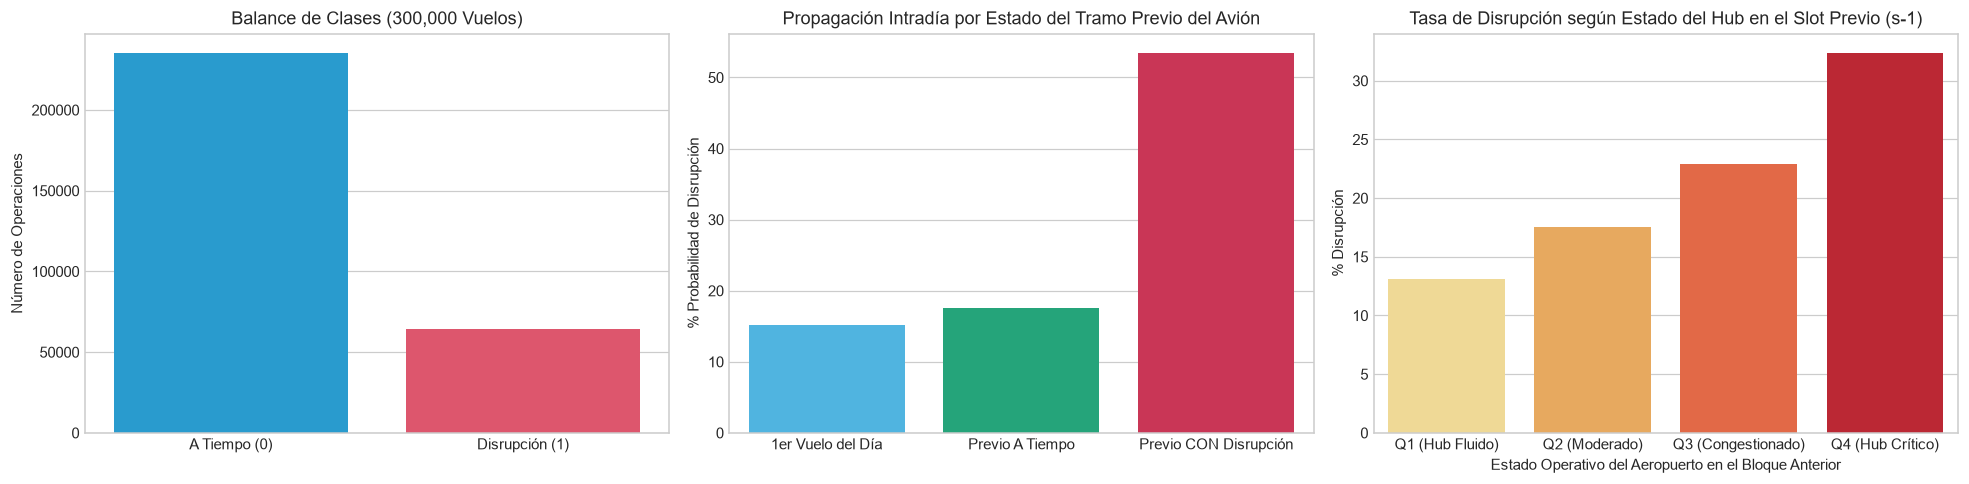

In [3]:
target_counts = df['is_delayed_or_cancelled'].value_counts()
target_pct = df['is_delayed_or_cancelled'].value_counts(normalize=True) * 100

print("=" * 72)
print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO:")
for val, count, pct in zip(target_counts.index, target_counts.values, target_pct.values):
    label = "Disrupción (Retraso >=15m / Cancelado)" if val == 1 else "A Tiempo / Retraso Menor (<15m)"
    print(f"  Clase {val} ({label:<38}): {count:>7,} ({pct:>5.2f}%)")
print("=" * 72)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Proporción de clases
sns.barplot(x=['A Tiempo (0)', 'Disrupción (1)'], y=target_counts.values, palette=['#0ea5e9', '#f43f5e'], ax=axes[0])
axes[0].set_title("Balance de Clases (300,000 Vuelos)")
axes[0].set_ylabel("Número de Operaciones")

# 2. Impacto de Disrupción en el Tramo Previo del Mismo Día (Turnaround Propagation)
df['prev_leg_status'] = np.where(
    df['tail_has_sameday_prev'] == 0,
    '1er Vuelo del Día',
    np.where(df['tail_sameday_prev_disrupted'] >= 1, 'Previo CON Disrupción', 'Previo A Tiempo')
)
order_leg = ['1er Vuelo del Día', 'Previo A Tiempo', 'Previo CON Disrupción']
leg_rate = df.groupby('prev_leg_status')['is_delayed_or_cancelled'].mean().reindex(order_leg) * 100
sns.barplot(x=leg_rate.index, y=leg_rate.values, palette=['#38bdf8', '#10b981', '#e11d48'], ax=axes[1])
axes[1].set_title("Propagación Intradía por Estado del Tramo Previo del Avión")
axes[1].set_xlabel("")
axes[1].set_ylabel("% Probabilidad de Disrupción")

# 3. Impacto de la Congestión Previa del Hub (Cuartiles de hub_dep_prev_disrupt_rate)
df['hub_prev_q'] = pd.qcut(df['hub_dep_prev_disrupt_rate']. rank(method='first'), q=4, labels=['Q1 (Hub Fluido)', 'Q2 (Moderado)', 'Q3 (Congestionado)', 'Q4 (Hub Crítico)'])
hub_q_rate = df.groupby('hub_prev_q', observed=False)['is_delayed_or_cancelled'].mean() * 100
sns.barplot(x=hub_q_rate.index.astype(str), y=hub_q_rate.values, palette='YlOrRd', ax=axes[2])
axes[2].set_title("Tasa de Disrupción según Estado del Hub en el Slot Previo (s-1)")
axes[2].set_xlabel("Estado Operativo del Aeropuerto en el Bloque Anterior")
axes[2].set_ylabel("% Disrupción")

plt.tight_layout()
plt.show()


## 3. Ingeniería de Características de Dominio Aeronáutico y Pipeline Preprocesador
Construimos las **70 características predictivas** combinando:
- **10 Variables de Alta Cardinalidad e Interacciones Espacio-Temporales** con `TargetEncoder(smooth='auto', cv=StratifiedKFold(5))`.
- **3 Variables Categóricas Operativas** con `OneHotEncoder`.
- **57 Variables Numéricas Escaladas** (22 señales causales de red y rotación intradía $s-1$, 14 señales meteorológicas origen/destino, 5 métricas de densidad de slots y 16 transformaciones físicas y cíclicas).


In [4]:
slot_order_map = {'MORNING': 1, 'AFTERNOON': 2, 'EVENING': 3, 'NIGHT': 4}

lag_cols = [
    'hub_dep_prev_disrupt_rate', 'hub_dep_prev_avg_delay', 'hub_dep_prev_cancel_rate',
    'hub_dep_prev_wx_delay', 'hub_dep_prev_nas_delay', 'hub_dep_prev_late_ac_delay', 'hub_dep_roll3_disrupt_rate',
    'hub_arr_prev_disrupt_rate', 'hub_arr_prev_avg_delay', 'hub_arr_prev_nas_delay',
    'air_dep_prev_disrupt_rate', 'air_dep_prev_avg_delay',
    'air_sys_prev_disrupt_rate', 'air_sys_prev_avg_delay',
    'tail_sameday_prev_dep_delay', 'tail_sameday_prev_arr_delay', 'tail_sameday_prev_disrupted', 'tail_has_sameday_prev',
    'tail_prev_dep_delay', 'tail_prev_arr_delay', 'tail_prev_disrupted', 'tail_roll3_disrupted'
]

def engineer_aviation_features(data: pd.DataFrame) -> pd.DataFrame:
    """Transforma variables crudas y rezagos causales en el espacio completo de 70 características."""
    d = data.copy()
    for col in ['dep_airport', 'arr_airport', 'airline', 'Manufacturer', 'Model', 'DepTime_label', 'Distance_type']:
        d[col] = d[col].fillna('UNKNOWN').astype(str).str.strip().str.upper()

    for col in lag_cols + ['tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'pres',
                           'arr_tavg', 'arr_tmin', 'arr_tmax', 'arr_prcp', 'arr_snow', 'arr_wspd', 'arr_pres',
                           'Aircraft_age', 'Flight_Duration']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
        d[col] = d[col].fillna(0.0 if col.startswith('tail_') else d[col].median()).astype('float32')

    d['slot_order'] = d['DepTime_label'].map(slot_order_map).fillna(2).astype('int8')
    d['route'] = d['dep_airport'] + '_' + d['arr_airport']
    d['dep_x_time'] = d['dep_airport'] + '_' + d['DepTime_label']
    d['arr_x_time'] = d['arr_airport'] + '_' + d['DepTime_label']
    d['airline_x_time'] = d['airline'] + '_' + d['DepTime_label']
    d['dep_x_month'] = d['dep_airport'] + '_' + d['Month'].astype(str)
    d['airline_x_dep'] = d['airline'] + '_' + d['dep_airport']

    d['deicing_risk'] = ((d['tmin'] <= 0.0) & ((d['prcp'] > 0.0) | (d['snow'] > 0.0))).astype('int8')
    d['temp_swing'] = (d['tmax'] - d['tmin']).astype('float32')
    d['total_route_prcp'] = (d['prcp'] + d['arr_prcp']).astype('float32')
    d['total_route_snow'] = (d['snow'] + d['arr_snow']).astype('float32')
    d['max_route_wind'] = np.maximum(d['wspd'], d['arr_wspd']).astype('float32')
    d['pres_drop'] = np.maximum(0.0, 1013.25 - d['pres']).astype('float32')
    d['arr_pres_drop'] = np.maximum(0.0, 1013.25 - d['arr_pres']).astype('float32')

    d['sin_month'] = np.sin(2 * np.pi * d['Month'] / 12.0).astype('float32')
    d['cos_month'] = np.cos(2 * np.pi * d['Month'] / 12.0).astype('float32')
    d['sin_dow'] = np.sin(2 * np.pi * d['Day_Of_Week'] / 7.0).astype('float32')
    d['cos_dow'] = np.cos(2 * np.pi * d['Day_Of_Week'] / 7.0).astype('float32')
    return d

df_feat = engineer_aviation_features(df)

target_encode_cols = [
    'dep_airport', 'arr_airport', 'airline', 'Model',
    'route', 'dep_x_time', 'arr_x_time', 'airline_x_time', 'dep_x_month', 'airline_x_dep'
]
onehot_cols = ['DepTime_label', 'Distance_type', 'Manufacturer']
numeric_cols = lag_cols + [
    'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'pres',
    'arr_tavg', 'arr_tmin', 'arr_tmax', 'arr_prcp', 'arr_snow', 'arr_wspd', 'arr_pres',
    'dep_slot_flights', 'arr_slot_flights', 'dep_daily_flights', 'aircraft_daily_legs', 'slot_order',
    'Aircraft_age', 'Flight_Duration', 'Day_Of_Week', 'Month', 'Is_Weekend',
    'deicing_risk', 'temp_swing', 'total_route_prcp', 'total_route_snow',
    'max_route_wind', 'pres_drop', 'arr_pres_drop', 'sin_month', 'cos_month', 'sin_dow', 'cos_dow'
]

feature_cols = target_encode_cols + onehot_cols + numeric_cols
X = df_feat[feature_cols].copy()
y = df_feat['is_delayed_or_cancelled'].copy()

cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
preprocessor = ColumnTransformer(
    transformers=[
        ('te', TargetEncoder(smooth='auto', cv=cv_splitter), target_encode_cols),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), onehot_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Total de características en el modelo: {len(feature_cols)}")
print(f"  • Target Encoding Bayesiano (OOF): {len(target_encode_cols)} variables")
print(f"  • One-Hot Encoding:                {len(onehot_cols)} variables")
print(f"  • Numéricas (Rezagos + Clima):     {len(numeric_cols)} variables")
print(f"Partición Train: {X_train.shape[0]:,} vuelos | Test: {X_test.shape[0]:,} vuelos")


Total de características en el modelo: 70
  • Target Encoding Bayesiano (OOF): 10 variables
  • One-Hot Encoding:                3 variables
  • Numéricas (Rezagos + Clima):     57 variables
Partición Train: 240,000 vuelos | Test: 60,000 vuelos


## 4. Entrenamiento y Comparación de Modelos
Comparamos dos arquitecturas sobre las 70 características:
1. **Regresión Logística Regularizada (`LogisticRegression`)**: Modelo lineal de referencia.
2. **Árboles Potenciados por Gradiente (`HistGradientBoostingClassifier`)**: Configurado con `max_iter=600`, `learning_rate=0.045`, `max_depth=12`, `max_leaf_nodes=63`, `min_samples_leaf=25`, regularización $L_2 = 1.5$ y parada temprana (`early_stopping=True`).


In [5]:
# 4.1 Modelo 1: Regresión Logística
print("Entrenando Modelo 1: Regresión Logística...")
pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, C=0.5, random_state=42))
])
pipe_lr.fit(X_train, y_train)
y_proba_lr = pipe_lr.predict_proba(X_test)[:, 1]
auc_lr = roc_auc_score(y_test, y_proba_lr)
pr_auc_lr = average_precision_score(y_test, y_proba_lr)
print(f"-> Regresión Logística     | ROC-AUC = {auc_lr:.4f} | PR-AUC = {pr_auc_lr:.4f}")

# 4.2 Modelo 2: HistGradientBoostingClassifier (Gradient Boosting Ensemble)
print()
print("Entrenando Modelo 2: HistGradientBoostingClassifier (Causal Network Ensemble)...")
pipe_hgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=600,
        learning_rate=0.045,
        max_depth=12,
        max_leaf_nodes=63,
        min_samples_leaf=25,
        l2_regularization=1.5,
        early_stopping=True,
        random_state=42
    ))
])
pipe_hgb.fit(X_train, y_train)
y_proba_hgb = pipe_hgb.predict_proba(X_test)[:, 1]
auc_hgb = roc_auc_score(y_test, y_proba_hgb)
pr_auc_hgb = average_precision_score(y_test, y_proba_hgb)
print(f"-> HistGradientBoosting    | ROC-AUC = {auc_hgb:.4f} | PR-AUC = {pr_auc_hgb:.4f}")


Entrenando Modelo 1: Regresión Logística...


-> Regresión Logística     | ROC-AUC = 0.7681 | PR-AUC = 0.5634

Entrenando Modelo 2: HistGradientBoostingClassifier (Causal Network Ensemble)...


-> HistGradientBoosting    | ROC-AUC = 0.7898 | PR-AUC = 0.6112


## 5. Optimización del Umbral de Decisión ($\tau$) y Evaluación Multimétrica
Auditamos el rendimiento del modelo en el conjunto de prueba (60,000 vuelos) a través de distintos regímenes operativos del Centro de Control (OCC):


COMPARATIVA DE REGÍMENES OPERATIVOS SEGÚN UMBRAL DE DECISIÓN (tau):
• Modo Max F1 / Sensibilidad       (tau=0.28) -> Precisión:  56.3% | Recall:  53.6% | F1: 0.5490 | Accuracy:  81.1%
• Modo Equilibrado Operativo       (tau=0.35) -> Precisión:  63.1% | Recall:  47.2% | F1: 0.5402 | Accuracy:  82.7%
• Modo Alta Precisión (Estándar)   (tau=0.50) -> Precisión:  73.2% | Recall:  36.9% | F1: 0.4910 | Accuracy:  83.6%
• Modo Precisión Crítica (OCC)     (tau=0.60) -> Precisión:  79.5% | Recall:  31.6% | F1: 0.4523 | Accuracy:  83.6%
• Modo Certeza Extrema (VIP/Crew)  (tau=0.70) -> Precisión:  85.2% | Recall:  25.2% | F1: 0.3895 | Accuracy:  83.0%


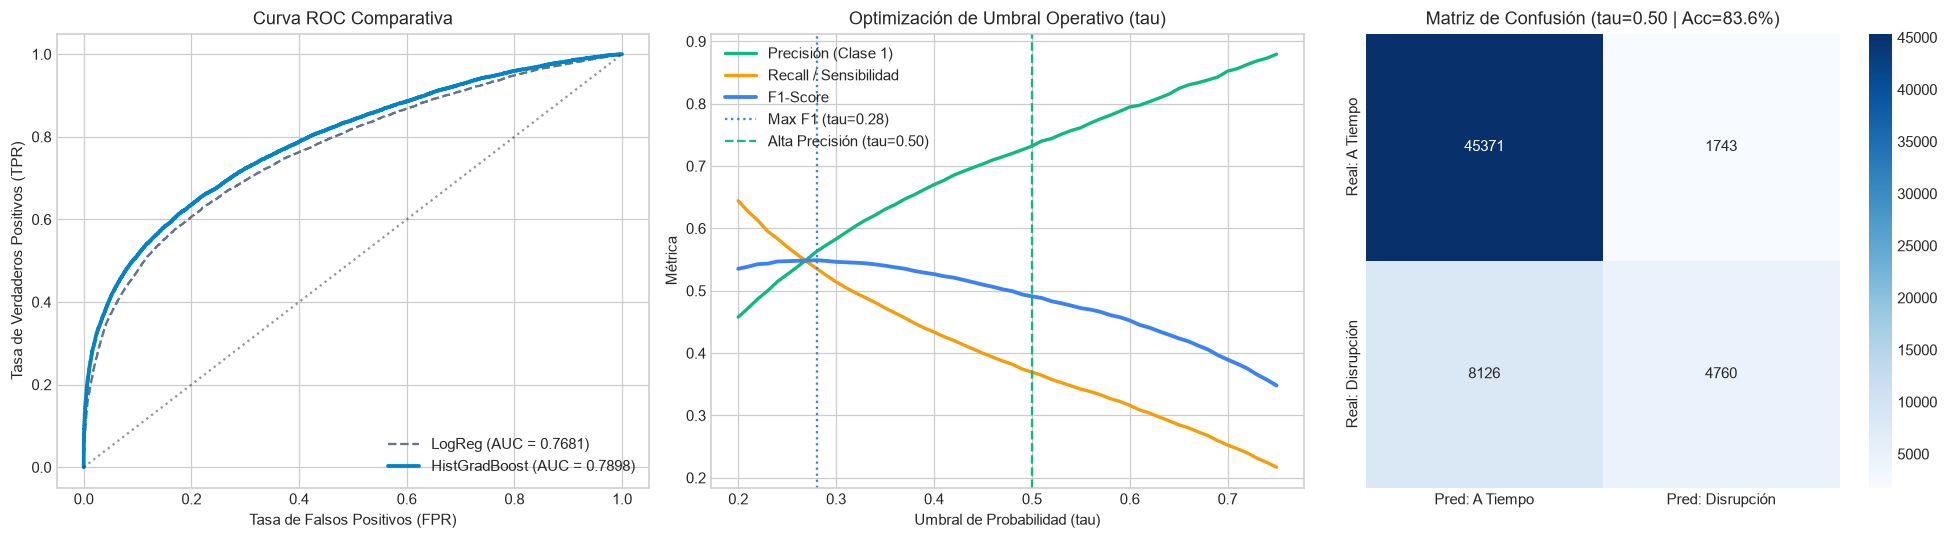

In [6]:
best_model = pipe_hgb
best_name = "HistGradientBoosting (Causal Network Ensemble)"
y_proba_best = y_proba_hgb

thresholds = np.linspace(0.20, 0.75, 56)
records = []
for t in thresholds:
    preds_t = (y_proba_best >= t).astype(int)
    records.append({
        'threshold': t,
        'precision': precision_score(y_test, preds_t, zero_division=0),
        'recall': recall_score(y_test, preds_t, zero_division=0),
        'f1': f1_score(y_test, preds_t, zero_division=0),
        'accuracy': accuracy_score(y_test, preds_t)
    })
df_thresh = pd.DataFrame(records)
best_f1_row = df_thresh.loc[df_thresh['f1'].idxmax()]
opt_f1_thresh = float(best_f1_row['threshold'])
high_prec_thresh = 0.50

print("=" * 85)
print("COMPARATIVA DE REGÍMENES OPERATIVOS SEGÚN UMBRAL DE DECISIÓN (tau):")
print("=" * 85)
for mode_name, t_val in [
    ("Modo Max F1 / Sensibilidad", opt_f1_thresh),
    ("Modo Equilibrado Operativo", 0.35),
    ("Modo Alta Precisión (Estándar)", 0.50),
    ("Modo Precisión Crítica (OCC)", 0.60),
    ("Modo Certeza Extrema (VIP/Crew)", 0.70)
]:
    p_bin = (y_proba_best >= t_val).astype(int)
    prec = precision_score(y_test, p_bin) * 100
    rec = recall_score(y_test, p_bin) * 100
    f1_v = f1_score(y_test, p_bin)
    acc = accuracy_score(y_test, p_bin) * 100
    print(f"• {mode_name:<32} (tau={t_val:.2f}) -> Precisión: {prec:>5.1f}% | Recall: {rec:>5.1f}% | F1: {f1_v:.4f} | Accuracy: {acc:>5.1f}%")
print("=" * 85)

y_pred_f1 = (y_proba_best >= opt_f1_thresh).astype(int)
y_pred_hp = (y_proba_best >= high_prec_thresh).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_hgb, tpr_hgb, _ = roc_curve(y_test, y_proba_hgb)
axes[0].plot(fpr_lr, tpr_lr, label=f"LogReg (AUC = {auc_lr:.4f})", color='#64748b', linestyle='--')
axes[0].plot(fpr_hgb, tpr_hgb, label=f"HistGradBoost (AUC = {auc_hgb:.4f})", color='#0284c7', linewidth=2.5)
axes[0].plot([0, 1], [0, 1], 'k:', alpha=0.4)
axes[0].set_title("Curva ROC Comparativa")
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (TPR)")
axes[0].legend(loc="lower right")

# 2. Curva de Calibración de Umbrales
axes[1].plot(df_thresh['threshold'], df_thresh['precision'], label='Precisión (Clase 1)', color='#10b981', linewidth=2.2)
axes[1].plot(df_thresh['threshold'], df_thresh['recall'], label='Recall / Sensibilidad', color='#f59e0b', linewidth=2.2)
axes[1].plot(df_thresh['threshold'], df_thresh['f1'], label='F1-Score', color='#3b82f6', linewidth=2.5)
axes[1].axvline(opt_f1_thresh, color='#3b82f6', linestyle=':', label=f'Max F1 (tau={opt_f1_thresh:.2f})')
axes[1].axvline(high_prec_thresh, color='#10b981', linestyle='--', label=f'Alta Precisión (tau={high_prec_thresh:.2f})')
axes[1].set_title("Optimización de Umbral Operativo (tau)")
axes[1].set_xlabel("Umbral de Probabilidad (tau)")
axes[1].set_ylabel("Métrica")
axes[1].legend(loc="best")

# 3. Matriz de Confusión en Modo Alta Precisión
cm = confusion_matrix(y_test, y_pred_hp)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Pred: A Tiempo', 'Pred: Disrupción'],
            yticklabels=['Real: A Tiempo', 'Real: Disrupción'])
axes[2].set_title(f"Matriz de Confusión (tau={high_prec_thresh:.2f} | Acc={accuracy_score(y_test, y_pred_hp)*100:.1f}%)")

plt.tight_layout()
plt.show()


## 6. Importancia de Características (Permutation Importance)
Cuantificamos el impacto real de cada variable sobre el ROC-AUC en el conjunto de prueba.


Calculando importancia de características mediante permutación en test set...


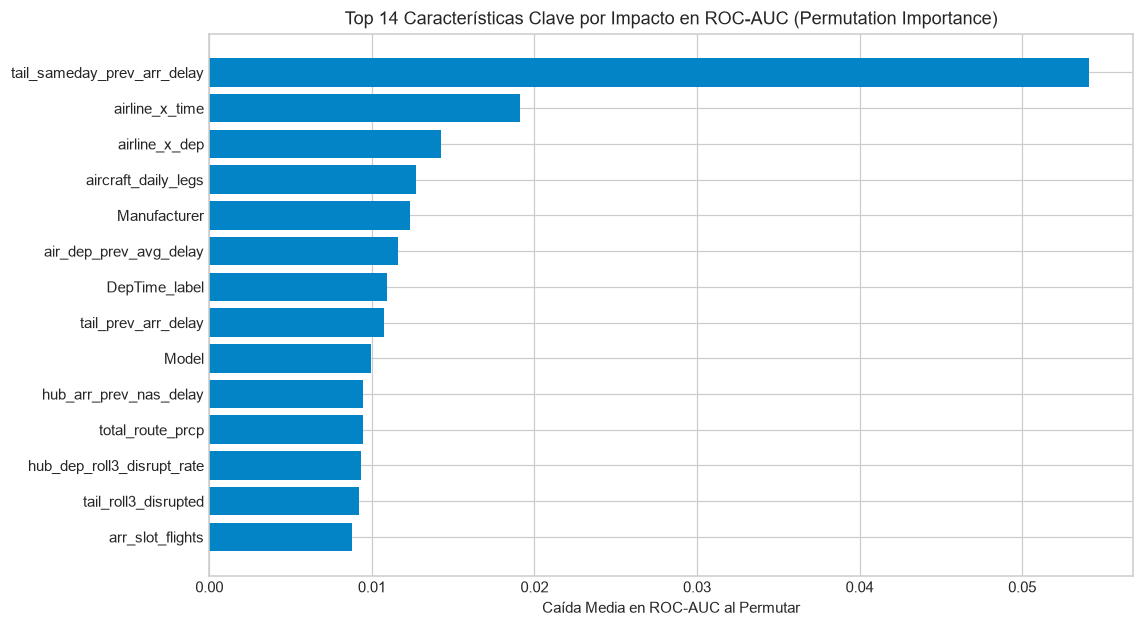

In [7]:
print("Calculando importancia de características mediante permutación en test set...")
perm_result = permutation_importance(
    best_model, X_test, y_test,
    scoring='roc_auc', max_samples=6000, n_repeats=5, random_state=42, n_jobs=-1
)

top_indices = perm_result.importances_mean.argsort()[::-1][:14]
top_features = [X_test.columns[i] for i in top_indices]
top_scores = perm_result.importances_mean[top_indices]

plt.figure(figsize=(10.5, 5.8))
plt.barh(top_features[::-1], top_scores[::-1], color='#0284c7')
plt.title("Top 14 Características Clave por Impacto en ROC-AUC (Permutation Importance)")
plt.xlabel("Caída Media en ROC-AUC al Permutar")
plt.tight_layout()
plt.show()


## 7. Serialización del Artefacto Predictivo y Tablas de Referencia para Inferencia en Tiempo Real
Guardamos el pipeline entrenado junto con los valores estadísticos de referencia por aeropuerto y aerolínea en `models/flight_delay_predictor.joblib`.


In [8]:
model_artifact_path = config.MODELS_DIR / "flight_delay_predictor.joblib"

airport_defaults = df_feat.groupby('dep_airport').agg(
    arr_tavg=('tavg', 'median'),
    arr_tmin=('tmin', 'median'),
    arr_tmax=('tmax', 'median'),
    arr_prcp=('prcp', 'median'),
    arr_snow=('snow', 'median'),
    arr_wspd=('wspd', 'median'),
    arr_pres=('pres', 'median'),
    dep_slot_flights=('dep_slot_flights', 'median'),
    dep_daily_flights=('dep_daily_flights', 'median'),
    hub_dep_prev_disrupt_rate=('hub_dep_prev_disrupt_rate', 'median'),
    hub_dep_prev_avg_delay=('hub_dep_prev_avg_delay', 'median'),
    hub_dep_prev_cancel_rate=('hub_dep_prev_cancel_rate', 'median'),
    hub_dep_prev_wx_delay=('hub_dep_prev_wx_delay', 'median'),
    hub_dep_prev_nas_delay=('hub_dep_prev_nas_delay', 'median'),
    hub_dep_prev_late_ac_delay=('hub_dep_prev_late_ac_delay', 'median'),
    hub_dep_roll3_disrupt_rate=('hub_dep_roll3_disrupt_rate', 'median')
).to_dict(orient='index')

airline_defaults = df_feat.groupby('airline').agg(
    Manufacturer=('Manufacturer', lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else 'BOEING'),
    Model=('Model', lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else '737 NG'),
    Aircraft_age=('Aircraft_age', 'median'),
    aircraft_daily_legs=('aircraft_daily_legs', 'median'),
    air_sys_prev_disrupt_rate=('air_sys_prev_disrupt_rate', 'median'),
    air_sys_prev_avg_delay=('air_sys_prev_avg_delay', 'median')
).to_dict(orient='index')

p_hp = (y_proba_best >= high_prec_thresh).astype(int)
p_f1 = (y_proba_best >= opt_f1_thresh).astype(int)
p_60 = (y_proba_best >= 0.60).astype(int)
p_70 = (y_proba_best >= 0.70).astype(int)

payload = {
    'model_name': best_name,
    'pipeline': best_model,
    'features': feature_cols,
    'target_encode_cols': target_encode_cols,
    'onehot_cols': onehot_cols,
    'numeric_features': numeric_cols,
    'categorical_features': target_encode_cols + onehot_cols,
    'top_airports': sorted(df_feat['dep_airport'].unique().tolist()),
    'optimal_f1_threshold': opt_f1_thresh,
    'high_precision_threshold': high_prec_thresh,
    'airport_defaults': airport_defaults,
    'airline_defaults': airline_defaults,
    'feature_importance': dict(zip(top_features, [float(x) for x in top_scores])),
    'metrics': {
        'roc_auc': float(auc_hgb),
        'pr_auc': float(pr_auc_hgb),
        'f1_score': float(f1_score(y_test, p_f1)),
        'precision_balanced': float(precision_score(y_test, p_f1)),
        'recall_balanced': float(recall_score(y_test, p_f1)),
        'accuracy_balanced': float(accuracy_score(y_test, p_f1)),
        'precision_high': float(precision_score(y_test, p_hp)),
        'recall_high': float(recall_score(y_test, p_hp)),
        'accuracy_high': float(accuracy_score(y_test, p_hp)),
        'precision_critical': float(precision_score(y_test, p_60)),
        'recall_critical': float(recall_score(y_test, p_60)),
        'precision_ultra': float(precision_score(y_test, p_70)),
        'recall_ultra': float(recall_score(y_test, p_70))
    },
    'target_description': 'is_delayed_or_cancelled: 1 si Dep_Delay >= 15 o Cancelled == 1, 0 en caso contrario'
}

joblib.dump(payload, model_artifact_path)
print("=" * 78)
print(f" Artefacto Predictivo serializado con éxito en: {model_artifact_path}")
print(f"• Algoritmo:                    {best_name}")
print(f"• ROC-AUC (Test 60k):           {payload['metrics']['roc_auc']:.4f} (vs 0.7177 baseline)")
print(f"• PR-AUC:                       {payload['metrics']['pr_auc']:.4f} (vs 0.4410 baseline)")
print(f"• F1-Score (Modo Balanceado):   {payload['metrics']['f1_score']:.4f} (Precisión: {payload['metrics']['precision_balanced']*100:.1f}% | Recall: {payload['metrics']['recall_balanced']*100:.1f}%)")
print(f"• Precisión Estándar (tau=0.50): {payload['metrics']['precision_high']*100:.1f}% | Recall: {payload['metrics']['recall_high']*100:.1f}% | Accuracy: {payload['metrics']['accuracy_high']*100:.1f}%")
print(f"• Precisión Crítica (tau=0.60):  {payload['metrics']['precision_critical']*100:.1f}% | Recall: {payload['metrics']['recall_critical']*100:.1f}%")
print(f"• Precisión Extrema (tau=0.70):  {payload['metrics']['precision_ultra']*100:.1f}% | Recall: {payload['metrics']['recall_ultra']*100:.1f}%")
print("=" * 78)


 Artefacto Predictivo serializado con éxito en: G:\My Drive\repositorios de proyectos\procesamiento de datos de vuelos\models\flight_delay_predictor.joblib
• Algoritmo:                    HistGradientBoosting (Causal Network Ensemble)
• ROC-AUC (Test 60k):           0.7898 (vs 0.7177 baseline)
• PR-AUC:                       0.6112 (vs 0.4410 baseline)
• F1-Score (Modo Balanceado):   0.5490 (Precisión: 56.3% | Recall: 53.6%)
• Precisión Estándar (tau=0.50): 73.2% | Recall: 36.9% | Accuracy: 83.6%
• Precisión Crítica (tau=0.60):  79.5% | Recall: 31.6%
• Precisión Extrema (tau=0.70):  85.2% | Recall: 25.2%
